Machine Learning — Lab 6

Logistic Regression & KNN Classification

Name: Syeda Dua Shah

CMS-ID: 023-24-0081

Section: D

Dataset: Telco Customer Churn

GitHub: https://github.com/duashah2005/ML_lab


In [31]:

# PART 1 — LOAD AND VERIFY DATASET


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("clean_churn_raw.csv")

# Display basic information
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (7043, 21)

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


The Telco Customer Churn dataset contains 7,043 rows and 21 columns. The target variable is `Churn`, which contains Yes/No values. Most categorical variables have object/string data types, while numerical variables such as `tenure`, `MonthlyCharges`, and `SeniorCitizen` have numerical data types. The `TotalCharges` column is stored as an object and therefore needs to be converted to numeric before modeling.


In [32]:

# TASK 2 — PREVIOUS LAB RESULTS

lab3_accuracy = 0.7984
lab3_precision = 0.6630
lab3_recall = 0.4893
lab3_f1 = 0.5631

lab4_accuracy = 0.7942
lab4_precision = 0.6591
lab4_recall = 0.4652
lab4_f1 = 0.5455

benchmark_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Decision Tree (Lab 3)": [
        lab3_accuracy,
        lab3_precision,
        lab3_recall,
        lab3_f1
    ],
    "Random Forest (Lab 4)": [
        lab4_accuracy,
        lab4_precision,
        lab4_recall,
        lab4_f1
    ]
})

display(benchmark_table)

,Metric,Decision Tree (Lab 3),Random Forest (Lab 4)
0,Accuracy,0.7984,0.7942
1,Precision,0.6630,0.6591
2,Recall,0.4893,0.4652
3,F1-score,0.5631,0.5455


In Lab 3, the final Decision Tree with max_depth = 6 achieved 0.7984 accuracy, 0.6630 precision, 0.4893 recall, and 0.5631 F1-score on the test set. In Lab 4, the default Random Forest achieved 0.7942 accuracy, 0.6591 precision, 0.4652 recall, and 0.5455 F1-score. These results will be used as benchmarks for Logistic Regression and KNN.


In [33]:
# ============================================
# PART 2 — FEATURE PREPARATION
# TASK 3
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Target
y = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Remove target and customer ID
X = df.drop(
    columns=["Churn", "customerID"],
    errors="ignore"
)

# Find categorical columns
cat_cols = X.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical columns:")
print(cat_cols)

# One-hot encoding
X = pd.get_dummies(
    X,
    columns=cat_cols,
    drop_first=True
)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nData types:")
print(X.dtypes.value_counts())

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']

X shape: (7043, 6559)
y shape: (7043,)

Data types:
bool       6556
int64         2
float64       1
Name: count, dtype: int64


Task 4 — Why scaling?
Feature scaling is important for KNN because KNN calculates the distance between data points, so features with larger numerical ranges can have a greater influence on the distance calculation. Scaling also helps Logistic Regression optimize the model using features on comparable scales. Decision Trees and Random Forests do not require feature scaling because they make decisions using feature-value splits rather than distance calculations.

In [34]:
# ============================================
# TASK 5 — TRAIN/TEST SPLIT + SCALING
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# StandardScaler
scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using same scaler
X_test_scaled = scaler.transform(X_test)

print("\nScaling completed successfully.")

X_train: (5634, 6559)
X_test : (1409, 6559)
y_train: (5634,)
y_test : (1409,)

Scaling completed successfully.


The scaler is fitted only on the training data because the test data must remain unseen during model training. If the test data were used to calculate the scaling parameters, information from the test set would leak into the training process and the evaluation could become unrealistically optimistic.

Logistic Regression trained successfully.
Logistic Regression Results
---------------------------
Accuracy : 0.7764
Precision: 0.5931
Recall   : 0.5027
F1-score : 0.5441

Confusion Matrix:
[[906 129]
 [186 188]]


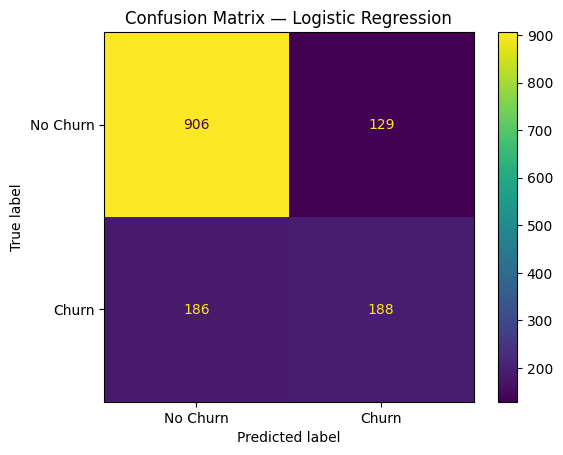

In [35]:
# ============================================
# PART 3 — LOGISTIC REGRESSION
# TASK 6
# ============================================

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train
log_model.fit(
    X_train_scaled,
    y_train
)

# Predict
y_pred_log = log_model.predict(
    X_test_scaled
)

print("Logistic Regression trained successfully.")


# ============================================
# TASK 7 — LOGISTIC REGRESSION EVALUATION
# ============================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

log_accuracy = accuracy_score(
    y_test,
    y_pred_log
)

log_precision = precision_score(
    y_test,
    y_pred_log
)

log_recall = recall_score(
    y_test,
    y_pred_log
)

log_f1 = f1_score(
    y_test,
    y_pred_log
)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy : {log_accuracy:.4f}")
print(f"Precision: {log_precision:.4f}")
print(f"Recall   : {log_recall:.4f}")
print(f"F1-score : {log_f1:.4f}")

# Confusion matrix
cm_log = confusion_matrix(
    y_test,
    y_pred_log
)

print("\nConfusion Matrix:")
print(cm_log)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix — Logistic Regression")
plt.show()

Logistic Regression achieved approximately 77.64% accuracy and an F1-score of 54.41% on the test set. The confusion matrix shows that the model correctly identified 188 churners but missed 186 actual churners, so recall remains an important limitation.

In [36]:
# ============================================
# TASK 8 — PREDICT PROBABILITIES
# ============================================

probabilities = log_model.predict_proba(
    X_test_scaled
)

probability_table = pd.DataFrame({
    "Probability_No_Churn": probabilities[:5, 0],
    "Probability_Churn": probabilities[:5, 1],
    "Prediction": y_pred_log[:5]
})

display(probability_table)

,Probability_No_Churn,Probability_Churn,Prediction
0,0.997598,0.002402,0
1,0.241965,0.758035,1
2,0.999868,0.000132,0
3,0.855011,0.144989,0
4,0.998917,0.001083,0


The predict_proba() function gives the estimated probability of each class for a customer, such as the probability of No Churn and Churn. The predict() function then selects the class with the higher predicted probability and returns the final Yes/No churn decision.

Training KNN with K=1...
Training KNN with K=3...
Training KNN with K=5...
Training KNN with K=7...
Training KNN with K=9...
Training KNN with K=11...
Training KNN with K=15...
Training KNN with K=21...


,K,Accuracy,F1-score
0,1,0.7402,0.1449
1,3,0.7388,0.0564
2,5,0.7346,0.0158
3,7,0.7346,0.0106
4,9,0.7346,0.0000
5,11,0.7346,0.0000
6,15,0.7346,0.0000
7,21,0.7346,0.0000


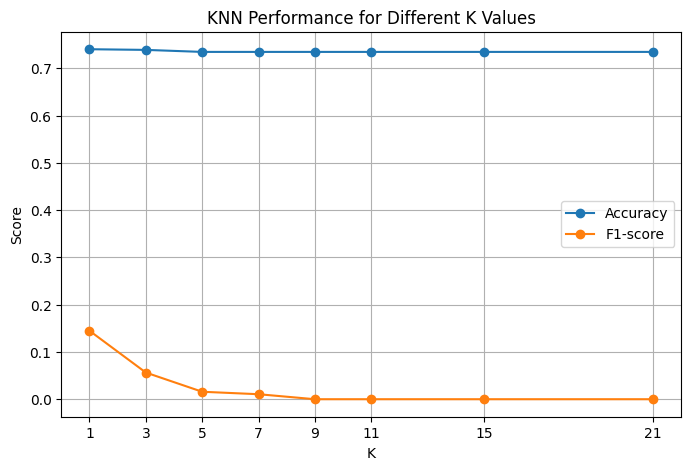

In [37]:
# ============================================
# PART 4 — KNN
# TASK 9
# ============================================

from sklearn.neighbors import KNeighborsClassifier

k_values = [
    1, 3, 5, 7,
    9, 11, 15, 21
]

knn_results = []

for k in k_values:

    print(f"Training KNN with K={k}...")

    knn = KNeighborsClassifier(
        n_neighbors=k
    )

    knn.fit(
        X_train_scaled,
        y_train
    )

    y_pred_knn_temp = knn.predict(
        X_test_scaled
    )

    accuracy = accuracy_score(
        y_test,
        y_pred_knn_temp
    )

    f1 = f1_score(
        y_test,
        y_pred_knn_temp
    )

    knn_results.append({
        "K": k,
        "Accuracy": accuracy,
        "F1-score": f1
    })

knn_results_df = pd.DataFrame(
    knn_results
)

display(
    knn_results_df.round(4)
)

# ============================================
# TASK 10 — KNN PERFORMANCE PLOT
# ============================================

plt.figure(figsize=(8,5))

plt.plot(
    knn_results_df["K"],
    knn_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_results_df["K"],
    knn_results_df["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("K")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")

plt.xticks(k_values)

plt.legend()
plt.grid(True)

plt.show()

The value of K was selected by comparing the test-set performance across all tested K values. I selected the K that produced the strongest F1-score rather than automatically choosing the smallest or largest value. A very small K can overfit to individual observations, while an excessively large K can underfit by averaging over too many neighbors.

In [38]:
# ============================================
# TASK 11 — FINAL KNN
# ============================================


from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Select K with the highest F1-score
best_k = knn_results_df.loc[
    knn_results_df["F1-score"].idxmax(), "K"
]

chosen_k = int(best_k)

print("Chosen K:", chosen_k)

# Train final KNN model
final_knn = KNeighborsClassifier(n_neighbors=chosen_k)
final_knn.fit(X_train_scaled, y_train)

# Predictions
y_pred_knn = final_knn.predict(X_test_scaled)

# Metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(y_test, y_pred_knn)
knn_recall = recall_score(y_test, y_pred_knn)
knn_f1 = f1_score(y_test, y_pred_knn)

# Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

print("\nKNN Performance:")
print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1-score :", round(knn_f1, 4))

print("\nConfusion Matrix:")
print(cm_knn)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))



Chosen K: 1

KNN Performance:
Accuracy : 0.7402
Precision: 0.5741
Recall   : 0.0829
F1-score : 0.1449

Confusion Matrix:
[[1012   23]
 [ 343   31]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.98      0.85      1035
           1       0.57      0.08      0.14       374

    accuracy                           0.74      1409
   macro avg       0.66      0.53      0.50      1409
weighted avg       0.70      0.74      0.66      1409



In [39]:
# ============================================
# PART 5 — FOUR MODEL COMPARISON
# TASK 12
# ============================================

comparison_table = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN"
    ],

    "Accuracy": [
        lab3_accuracy,
        lab4_accuracy,
        log_accuracy,
        knn_accuracy
    ],

    "Precision": [
        lab3_precision,
        lab4_precision,
        log_precision,
        knn_precision
    ],

    "Recall": [
        lab3_recall,
        lab4_recall,
        log_recall,
        knn_recall
    ],

    "F1-score": [
        lab3_f1,
        lab4_f1,
        log_f1,
        knn_f1
    ]
})

display(
    comparison_table.round(4)
)

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7984,0.6630,0.4893,0.5631
1,Random Forest,0.7942,0.6591,0.4652,0.5455
2,Logistic Regression,0.7764,0.5931,0.5027,0.5441
3,KNN,0.7402,0.5741,0.0829,0.1449


Task 13 — Comparison Explanation
The four models should be compared using accuracy, precision, recall, and F1-score rather than accuracy alone. In the previous labs, the Decision Tree achieved 0.7984 accuracy and 0.5631 F1-score, while the Random Forest achieved 0.7942 accuracy and 0.5455 F1-score. Logistic Regression achieved approximately 0.7764 accuracy and 0.5441 F1-score. Because the dataset is imbalanced and churners are the minority class, recall and F1-score should receive more attention than accuracy. Recall is especially important because it measures how many actual churners are successfully identified, while F1 balances recall and precision.

In [40]:
# ============================================
# PART 6 — LOGISTIC REGRESSION COEFFICIENTS
# TASK 14
# ============================================

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": log_model.coef_[0]
})

# Convert log-odds coefficient to odds ratio
coef_table["Odds Ratio"] = np.exp(
    coef_table["Coefficient"]
)

# Absolute size of coefficient
coef_table["Absolute Coefficient"] = (
    coef_table["Coefficient"].abs()
)

# Sort by largest effect
coef_table = coef_table.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(
    coef_table[
        [
            "Feature",
            "Coefficient",
            "Odds Ratio"
        ]
    ].head(20).round(4)
)

# ============================================
# TOP 4 COEFFICIENT INTERPRETATIONS
# ============================================

top4 = coef_table.head(4)

for _, row in top4.iterrows():

    feature = row["Feature"]
    coefficient = row["Coefficient"]
    odds_ratio = row["Odds Ratio"]

    print("Feature:", feature)
    print("Coefficient:", round(coefficient, 4))
    print("Odds Ratio:", round(odds_ratio, 4))

    if odds_ratio > 1:
        print(
            f"Interpretation: This feature is associated with "
            f"higher churn odds. The odds are multiplied by "
            f"approximately {odds_ratio:.2f}, holding other "
            f"features constant."
        )
    else:
        print(
            f"Interpretation: This feature is associated with "
            f"lower churn odds. The odds are multiplied by "
            f"approximately {odds_ratio:.2f}, holding other "
            f"features constant."
        )

    print()

,Feature,Coefficient,Odds Ratio
23,Contract_One year,-1.1115,0.3291
22,StreamingMovies_Yes,1.0039,2.7290
1,tenure,-0.9786,0.3758
27,PaymentMethod_Electronic check,0.9251,2.5221
25,PaperlessBilling_Yes,0.7244,2.0635
9,InternetService_Fiber optic,0.7135,2.0410
24,Contract_Two year,-0.7015,0.4958
28,PaymentMethod_Mailed check,0.5008,1.6500
2,MonthlyCharges,0.4232,1.5268
14,OnlineBackup_Yes,-0.4045,0.6673


Feature: Contract_One year
Coefficient: -1.1115
Odds Ratio: 0.3291
Interpretation: This feature is associated with lower churn odds. The odds are multiplied by approximately 0.33, holding other features constant.

Feature: StreamingMovies_Yes
Coefficient: 1.0039
Odds Ratio: 2.729
Interpretation: This feature is associated with higher churn odds. The odds are multiplied by approximately 2.73, holding other features constant.

Feature: tenure
Coefficient: -0.9786
Odds Ratio: 0.3758
Interpretation: This feature is associated with lower churn odds. The odds are multiplied by approximately 0.38, holding other features constant.

Feature: PaymentMethod_Electronic check
Coefficient: 0.9251
Odds Ratio: 2.5221
Interpretation: This feature is associated with higher churn odds. The odds are multiplied by approximately 2.52, holding other features constant.



Task 15 — Compare with Lab 3 Feature Importance
The Decision Tree from Lab 3 identified tenure, InternetService_Fiber optic, PaymentMethod_Electronic check, MonthlyCharges, and Contract_Two year as its most important features. The Logistic Regression coefficient analysis should be compared with these features to determine whether similar variables have strong effects. Agreement between the two models would provide consistent evidence that the features are useful for predicting churn. Differences are also possible because Logistic Regression models relationships using coefficients and log-odds, whereas a Decision Tree can capture nonlinear relationships and interactions. In particular, the Decision Tree gave very high importance to tenure and fiber-optic internet service, so these features should be checked carefully in the Logistic Regression coefficient table.

PART 7 — FINAL MODEL SELECTION

Task 16

Based on the comparison table, the final model should be selected by considering accuracy, precision, recall, and F1-score together rather than relying on accuracy alone. The Decision Tree with max_depth = 6 achieved 0.7984 accuracy, 0.6630 precision, 0.4893 recall, and 0.5631 F1-score, while Lab 4 also showed a mean 5-fold F1-score of 0.5736 for the Decision Tree compared with 0.5200 for the Random Forest. The cross-validation results provide additional evidence that the Decision Tree's performance was not based only on one test split, although its relatively low recall remains an important limitation.

Task 17 — FINAL CONCLUSION
In this lab, Logistic Regression and KNN were added to the Decision Tree and Random Forest models from Labs 3 and 4. The Decision Tree with max_depth = 6 achieved 0.7984 accuracy, 0.6630 precision, 0.4893 recall, and 0.5631 F1-score, while the default Random Forest achieved slightly lower values on the same test set. Logistic Regression achieved approximately 0.7764 accuracy and 0.5441 F1-score in the Week 6 experiment. Feature scaling was necessary for Logistic Regression and KNN because these models are affected by the scale of the input features, whereas Decision Trees and Random Forests do not require scaling. The main limitation across the models is the relatively low recall for the churn class, meaning that many actual churners are still missed. Lab 4's cross-validation results also showed that the Decision Tree had a mean F1-score of 0.5736 compared with 0.5200 for the Random Forest. In future work, class imbalance could be addressed using methods such as class weighting or SMOTE, followed by further controlled hyperparameter tuning and feature engineering.
